Opening some files to look at them

In [1]:
%matplotlib ipympl

In [2]:
from astropy.io import fits
import numpy as np
import matplotlib.pyplot as plt
import pickle

In [3]:
reductionNo = "01"
n1 = fits.open("../../../../../data/uncals/jw05022001001_04102_00001-seg001_nrs1_uncal.fits")

In [4]:
n1.info()

Filename: ../../../../../data/uncals/jw05022001001_04102_00001-seg001_nrs1_uncal.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     203   ()      
  1  SCI           1 ImageHDU        67   (512, 32, 5, 5160)   int16 (rescales to uint16)   
  2  GROUP         1 BinTableHDU     38   1720R x 13C   [J, I, I, J, I, 26A, I, I, I, I, 36A, D, D]   
  3  INT_TIMES     1 BinTableHDU     24   5160R x 7C   [J, D, D, D, D, D, D]   
  4  ASDF          1 BinTableHDU     11   1R x 1C   [8346B]   


In [5]:
nints,ngroups,nrows,ncols = n1["SCI"].shape
print(f"There are {nints} integrations of {ngroups} groups in {nrows} rows and {ncols} columns.")

There are 5160 integrations of 5 groups in 32 rows and 512 columns.


Create a median science image from the final group of every integration

In [6]:
n1_science = np.median([n1["SCI"].data[i][ngroups-1] for i in range(nints)],axis=0)

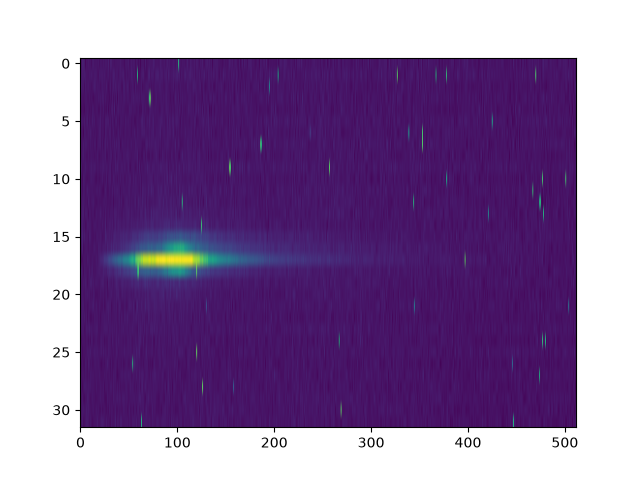

In [7]:
vmin,vmax = np.percentile(n1_science,[10,90])
plt.figure()
plt.imshow(n1_science,aspect="auto")#,vmin=vmin,vmax=vmax)
# plt.imshow(n1["SCI"].data[0][5])
plt.show()

OK, there are a few bad pixels here but also there's an odd background region at the top which might throw off a 1/f correction. I might want to make a narrower background region for the 1/f correction (not using full detector width).

In [8]:
from reduction_utils import cosmic_removal as c

In [9]:
np.median(n1_science)

np.float64(6765.0)

In [10]:
from scipy.signal import medfilt
from astropy.stats import median_absolute_deviation
mf_box_width = 5

median = np.array([medfilt(row,mf_box_width) for row in n1_science]) # running over 3 pixels
residuals = median - n1_science

cut_off = 10

good_pixels = ((residuals <= cut_off*median_absolute_deviation(residuals,ignore_nan=True)) & (residuals >= -cut_off*median_absolute_deviation(residuals,ignore_nan=True)))

good_pixels

array([[ True,  True,  True, ...,  True,  True,  True],
       [ True,  True,  True, ...,  True,  True,  True],
       [ True,  True,  True, ...,  True,  True,  True],
       ...,
       [ True,  True,  True, ...,  True,  True,  True],
       [ True,  True,  True, ...,  True,  True,  True],
       [ True,  True,  True, ...,  True,  True,  True]], shape=(32, 512))

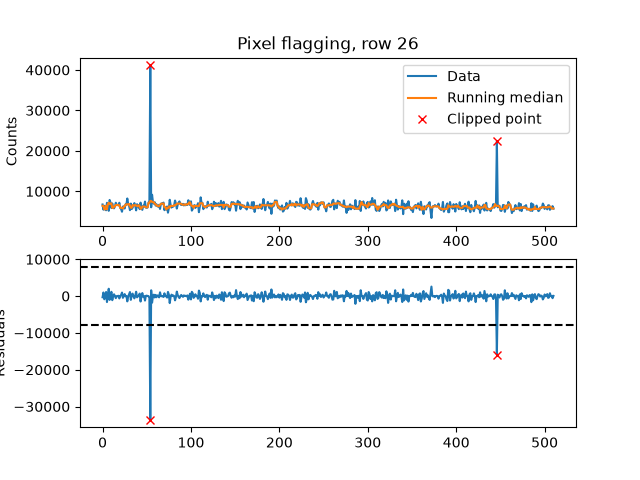

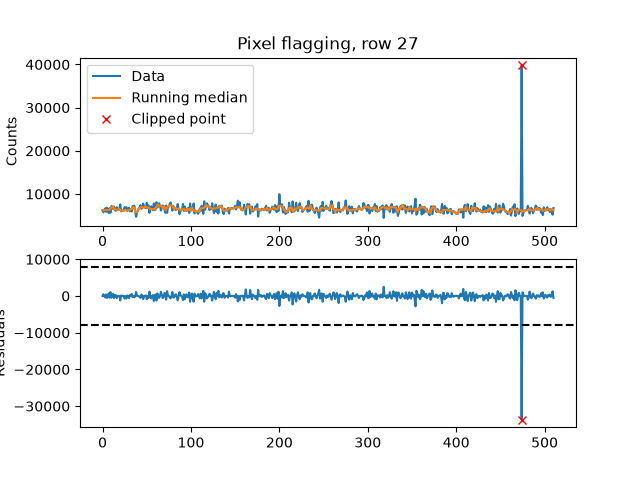

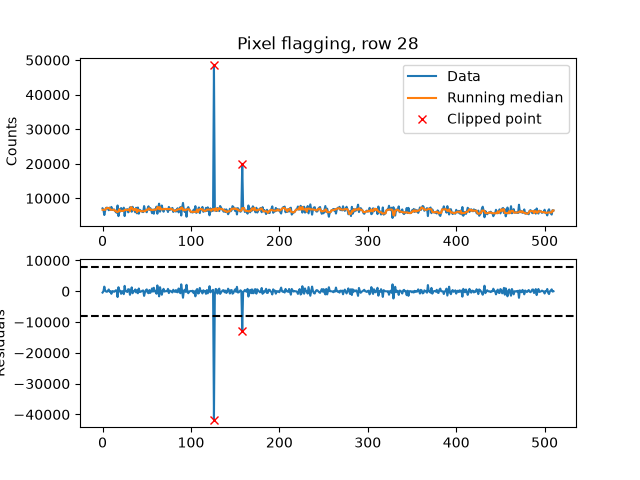

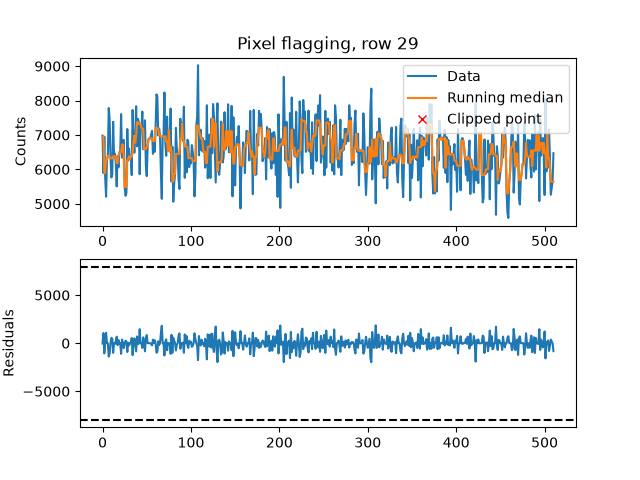

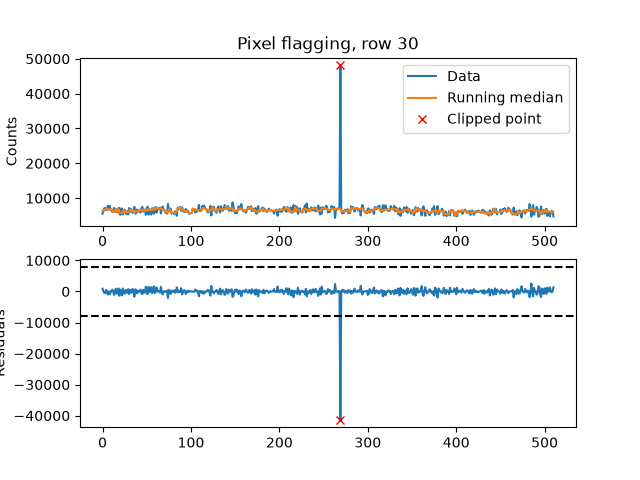

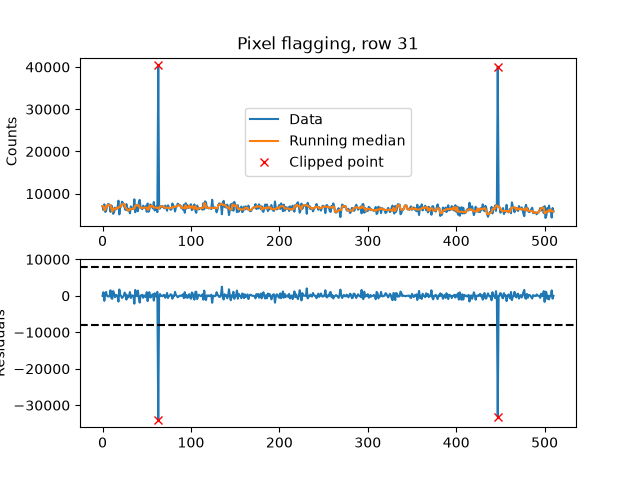

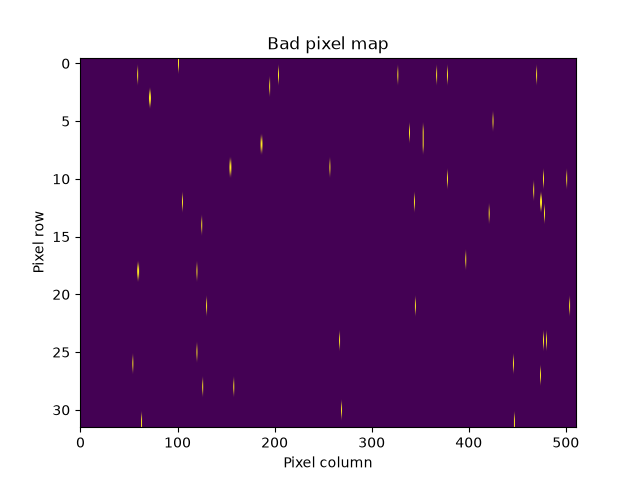

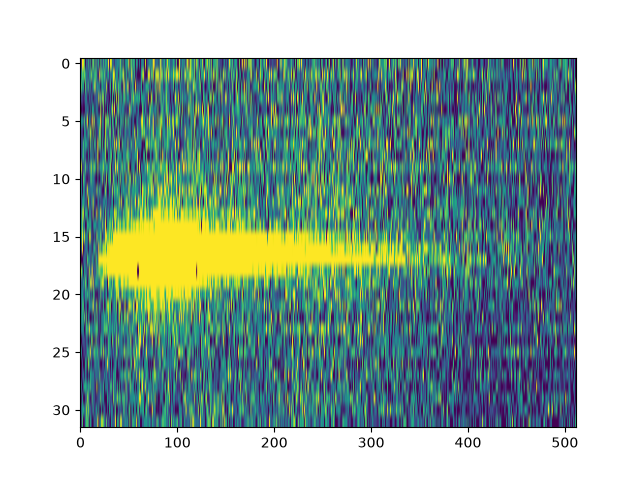

In [11]:
import importlib
importlib.reload(c)

n1_mask = c.flag_bad_pixels(n1_science,verbose=True,plot_rows=range(26,38),mf_box_width=5,cut_off=4,use_mad=False,\
                           max_pixels_per_row = 20)

# manually flagging additional pixels
# n1_mask[27,1544] = True
# n1_mask[38,616] = True

n1_science_masked = n1_science.copy()
n1_science_masked[n1_mask] = 0

vmin,vmax = np.percentile(n1_science_masked,[10,90])

plt.figure()
plt.imshow(n1_science_masked,aspect="auto",vmin=vmin,vmax=vmax)
plt.show()

OK, this pixel map looks to have done a decent job. This is the first time whereby I calculated the standard deviation across the full image residuals, not row-by-row which I think helped flag additional bad pixels.

In [12]:
pickle.dump(n1_mask,open(f"../../../../../data/reduction{reductionNo}/nircam_bad_pixel_mask.pickle","wb"))

In [13]:
n1_mask.shape

(32, 512)

In [14]:
n1.info()

Filename: ../../../../../data/uncals/jw05022001001_04102_00001-seg001_nrs1_uncal.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU     203   ()      
  1  SCI           1 ImageHDU        67   (512, 32, 5, 5160)   uint16   
  2  GROUP         1 BinTableHDU     38   1720R x 13C   [J, I, I, J, I, 26A, I, I, I, I, 36A, D, D]   
  3  INT_TIMES     1 BinTableHDU     24   5160R x 7C   [J, D, D, D, D, D, D]   
  4  ASDF          1 BinTableHDU     11   1R x 1C   [8346B]   


In [15]:
def save_new_fits(data,filename,original_header):
    # copy original header to new header
    new_header = original_header

    # make science extension
    hdu1 = fits.PrimaryHDU([data],header=new_header) # science array
    hdu1.name = "SCI"

    # make dummy error extension
    hdu2 = fits.ImageHDU(np.zeros_like([data]))
    hdu2.name = "ERR"

    # make dummy integration extension
    c3 = fits.Column(name='int_mid_BJD_TDB', array=np.array([0.]), format='K')
    hdu3 = fits.BinTableHDU.from_columns([c3])
    hdu3.name = "INT_TIMES"

    hdu = fits.HDUList([hdu1,hdu2,hdu3])
    print("saving %s"%filename)
    hdu.writeto(filename,overwrite=True)
    return hdu

In [16]:
master_uncal_n1 = save_new_fits(n1_science_masked,f"../../../../../data/reduction{reductionNo}/master_uncal.fits",n1[0].header) 

saving ../../../../../data/reduction01/master_uncal.fits


In [17]:
n1_science_masked.shape

(32, 512)

### Quick look white light curves

In [24]:
r01 = np.loadtxt("reduction01/white_light.dat")
r02 = np.loadtxt("reduction02/white_light.dat")
r03 = np.loadtxt("reduction03/white_light.dat")

from scipy.ndimage import gaussian_filter

<IPython.core.display.Javascript object>


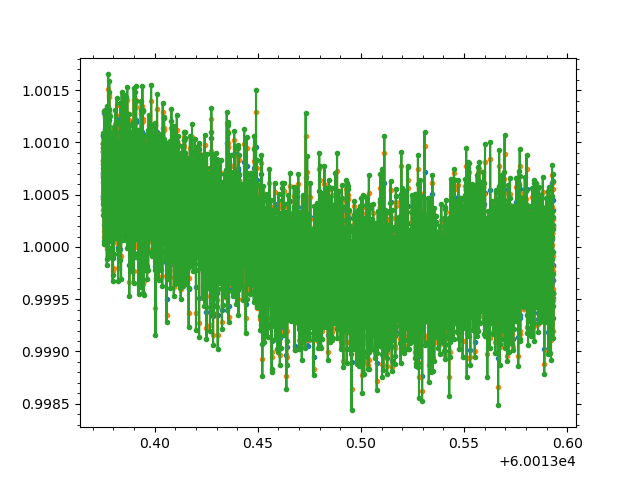

In [26]:
plt.figure()
plt.plot(r01[:,0],r01[:,1]/r01[:,1].mean(),label="reduction01",marker='.')
plt.plot(r02[:,0],r02[:,1]/r02[:,1].mean(),label="reduction02",marker='.')
plt.plot(r03[:,0],r03[:,1]/r03[:,1].mean(),label="reduction03",marker='.')
plt.show()

<IPython.core.display.Javascript object>


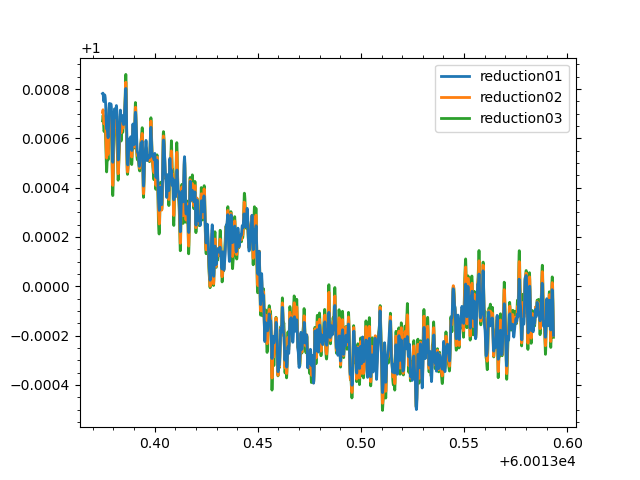

In [37]:
plt.figure()
# plt.plot(r01[:,0],r01[:,1]/r01[:,1].mean(),label="reduction01",marker='.',ls="None")
plt.plot(r01[:,0],gaussian_filter(r01[:,1]/r01[:,1].mean(),sigma=5),label="reduction01",lw=2,zorder=3)
plt.plot(r02[:,0],gaussian_filter(r02[:,1]/r02[:,1].mean(),sigma=5),label="reduction02",lw=2,zorder=2)
plt.plot(r03[:,0],gaussian_filter(r03[:,1]/r03[:,1].mean(),sigma=5),label="reduction03",lw=2,zorder=1)
plt.legend()
# plt.plot(r02[:,0],r02[:,1]/r02[:,1].mean(),label="reduction02",marker='.')
# plt.plot(r03[:,0],r03[:,1]/r03[:,1].mean(),label="reduction03",marker='.')
plt.show()

OK so all reductions give the same red noise but the lowest amplitude is with the narrower ap so this is the way to go, at least with these background assumptions

<IPython.core.display.Javascript object>


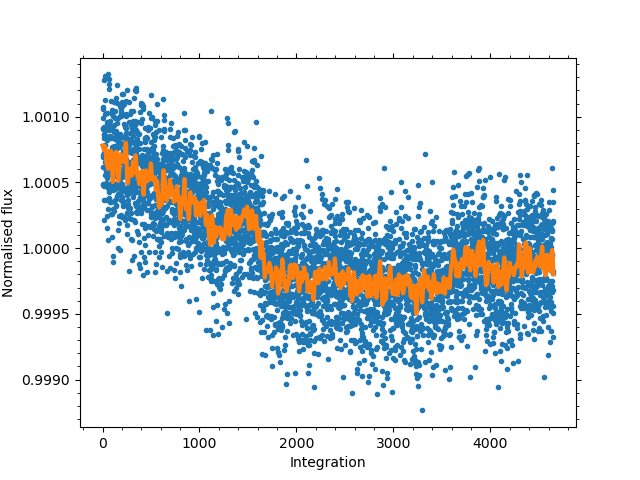

In [41]:
plt.figure()
plt.plot(r01[:,1]/r01[:,1].mean(),label="reduction01",marker='.',ls="None")
plt.plot(gaussian_filter(r01[:,1]/r01[:,1].mean(),sigma=5),label="reduction01",lw=3,zorder=3)
plt.xlabel("Integration")
plt.ylabel("Normalised flux")
plt.show()

In [43]:
r01[:,0]

array([60013.374709, 60013.374756, 60013.374803, ..., 60013.593228,
       60013.593275, 60013.593322])